<a href="https://colab.research.google.com/github/johanmorpar/Data_Science_Projects/blob/main/Scoring_Credito_CajaCompensacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo de scoring de crédito
### Una caja de compensación familiar colombiana · Johan Moreno
*Quinto Congreso de Ingeniería, Desarrollo Humano y Sostenibilidad Global (ETITC, Bogotá)*

## Introducción

**Problema de negocio.** Una caja de compensación decide a quién le otorga crédito apoyándose, en buena parte, en el criterio del analista y en el score de las centrales de riesgo. La pregunta es si **los datos que la propia caja ya tiene de sus afiliados** permiten estimar mejor quién va a incumplir.

**Qué hace este Notebook.** Recorre el proceso completo, estructura por estructura: primero convierte una base cruda en variables confiables (Parte A) y luego construye, compara y valida el modelo estadistico (Parte B). Cada sección sigue el mismo guion: la pregunta de negocio, el método estadístico, un código corto y la lectura del resultado.

## De 42 variables a 8: qué se hizo con cada una

| Qué pasó | Variables | Por qué |
|---|---|---|
| Se eliminaron | 4 | Identificadores (tipo y número de documento, ID y nombre de la empresa): no existen o no generalizan en un solicitante nuevo. |
| Definen el objetivo y el universo | 2 | `Estado_Cupo` define quién incumplió; `Cantidad_Cupo` indica quién tiene cupo. |
| Se excluyeron por falta de poder | 13 | Centrales de riesgo: son datos legítimos, pero no predicen el incumplimiento interno. |
| Se excluyeron por redundancia | 3 | Límite del cupo (lo fijó el analista), antigüedad laboral (casi idéntica a los meses de afiliación) y nivel educativo (se deriva del cargo). |
| Se probaron o se usaron solo para limpiar | 10 | Edad, actividad de la empresa y beneficiarios no mejoraron el AUC; la pirámide solo sirve para clasificar los cargos "Sin Definir"; los 6 montos de uso se resumen en el conteo de servicios. |
| **Entran al modelo** | **10 → 5 → 8** | Ingreso, cargo, segmento, fecha de afiliación (se vuelve meses) y 6 conteos de servicios (se vuelven un total): **5 variables**. Cargo (4 niveles) y segmento (3) se codifican en 3 y 2 columnas, y por eso el modelo ve **8 columnas**. |

### Metodología en siete etapas
1. **Depuración:** nombres, tipos, identificadores, datos faltantes.
2. **Variable objetivo:** incumplimiento definido con criterio de negocio; sin cupo significa *no observado*.
3. **fuga de información (*leakage*)** en las centrales de riesgo.
4. **Selección incremental de variables** con validación cruzada repetida (5 × 10).
5. **Segmentación K-Means (k = 8)** para saber a qué parte de la población representa el modelo.
6. **Comparación de once algoritmos** y prueba de significancia con la corrección de Nadeau y Bengio.
7. **Validación del modelo elegido:** calibración, razones de odds, bandas de riesgo y backtesting.

**Cómo usarlo.** En colab.research.google.com, pestaña *Subir*.

> **Confidencialidad.** Este cuaderno **no incluye datos**: se ejecuta con tu propia base y esta solo vive en la sesión.

# Parte A. Tratamiento de datos

## Radiografía de la base

**Pregunta de negocio.** ¿Qué tan confiable es lo que tenemos antes de modelar?
**Método.** Perfil de cada columna: tipo, porcentaje de nulos y variedad de valores. Las decisiones de limpieza salen de aquí.

In [5]:
import pandas as pd

def anonimizar_servicio(df):
    """Un servicio propio de la entidad delata cuál es: se renombra a 'Recreacion'."""
    conocidos = ('hoteleria', 'droguerias', 'escuelas_deportivas', 'agencia_viajes', 'convenios')
    for x in [c[:-9] for c in df.columns if c.lower().endswith('_cantidad') and c[:-9].lower() not in conocidos]:
        df = df.rename(columns={f'{x}_cantidad': 'Recreacion_cantidad', f'Uso_Promedio_{x} ': 'Uso_Promedio_Recreacion '})
    return df

In [6]:
RUTA = ''  #@param {type:"string"}
if not RUTA:                                   # en Colab abre el selector de archivos
    from google.colab import files
    RUTA = list(files.upload())[0]

crudo = anonimizar_servicio(pd.read_csv(RUTA, sep=';', encoding='utf-8-sig'))
perfil = pd.DataFrame({'tipo': crudo.dtypes.astype(str), 'nulos_%': (crudo.isna().mean() * 100).round(1),
                       'valores_distintos': crudo.nunique()})
print(f'{crudo.shape[0]:,} afiliados y {crudo.shape[1]} columnas')
perfil[(perfil['nulos_%'] > 1) | (perfil.valores_distintos <= 4)]

Saving Base_de_datos_Scoring__Credito_.csv to Base_de_datos_Scoring__Credito_ (1).csv
5,000 afiliados y 42 columnas


,tipo,nulos_%,valores_distintos
TIPO DE DOCUMENTO,object,0.0,4
ACTIVIDAD DE LA EMPRESA,object,3.7,20
ANTIGUEDAD EN MESES,float64,22.3,283
NIVEL EDUCATIVO,object,88.8,2
PIRAMIDE_NUEVA,object,22.3,9
CANTIDAD DE BENEFICIARIOS,float64,22.3,8
SEGMENTO_POBLACIONAL,object,22.3,4
Cantidad_Cupo,int64,0.0,2
Hoteleria_cantidad,int64,0.0,4
Recreacion_cantidad,int64,0.0,4


**Analisis.**
- El nivel educativo está **88,8% vacío**: casi no hay información que rescatar.
- Cuatro campos (antigüedad, pirámide, beneficiarios y segmento) comparten **exactamente el mismo 22,3% de nulos**. Faltan juntos en las mismas 1.115 personas, lo que apunta a un origen común en el registro.
- El tipo de documento casi no varía y el cupo solo toma dos valores. Además hay nombres con espacios escondidos, que se corrigen en la sección siguiente.

## Limpieza básica: nombres, tipos e identificadores

**Pregunta de negocio.** ¿Hay errores silenciosos que dañarían cualquier cálculo?
**Método.** Normalizar nombres (un espacio escondido hace fallar una referencia sin avisar), convertir tipos (el endeudamiento viene como texto con coma decimal y la fecha como texto) y retirar los identificadores, que no existen para un solicitante nuevo.

In [7]:
import re, unicodedata

def normalizar(c):
    c = unicodedata.normalize('NFKD', c).encode('ascii', 'ignore').decode()
    return re.sub(r'[\s_]+', '_', c.strip().lower())

d = crudo.rename(columns=normalizar)
d['endeudamiento_julio2024'] = pd.to_numeric(d['endeudamiento_julio2024'].astype(str).str.replace(',', '.'), errors='coerce')
d['fecha_de_afiliacion'] = pd.to_datetime(d['fecha_de_afiliacion'], dayfirst=True)
d = d.drop(columns=['tipo_de_documento', 'numero_de_documento', 'id_empresa', 'empresa_donde_labora'])

print(f"Columnas: {crudo.shape[1]} -> {d.shape[1]}")
print("Documento: cédula en", f"{(crudo['TIPO DE DOCUMENTO'] == 'CC').mean():.1%}", "de los casos")
print("Endeudamiento:", crudo['Endeudamiento_julio2024'].head(3).tolist(), '->', d['endeudamiento_julio2024'].head(3).tolist())

Columnas: 42 -> 38
Documento: cédula en 98.2% de los casos
Endeudamiento: ['0,55', '0,21', '0,26'] -> [0.55, 0.21, 0.26]


 Pasamos de 42 a 38 columnas. El tipo de documento no distingue a nadie (98,2% es cédula), y el número de documento y la empresa son propios de cada persona. El endeudamiento pasó de texto (`'0,55'`) a número y ya puede promediarse y modelarse. Estos errores son silenciosos: no generan una alerta, generan resultados vacíos o equivocados.

## Datos faltantes: nivel educativo y cargo "Sin Definir"

**Pregunta de negocio.** ¿Se puede rescatar información de campos casi vacíos o inciertos, o conviene descartarlos?
**Método.** Primero, verificar la coherencia del nivel educativo contra el cargo y reemplazarlo por una estimación. Segundo, no tratar el cargo "Sin Definir" como un grupo homogéneo: clasificarlo con ingreso, antigüedad y pirámide poblacional.

In [8]:
import numpy as np

por_cargo = {'Operativo': 'BACHILLERATO', 'Administrativo': 'TECNICO_TECNOLOGO', 'Staff': 'TECNICO_TECNOLOGO',
             'Técnico': 'TECNICO_TECNOLOGO', 'Profesional': 'UNIVERSITARIO', 'Directivo': 'POSGRADO',
             'Ejecutivo': 'POSGRADO', 'Representante Legal': 'POSGRADO', 'Servicio Domestico R': 'BASICA_SECUNDARIA'}
coherente = (((d.nivel_educativo == 'DOCTORADO') & d.cargo.isin(['Directivo', 'Ejecutivo', 'Profesional', 'Representante Legal']))
             | ((d.nivel_educativo == 'BACHILLERATO') & d.cargo.isin(['Operativo', 'Administrativo'])))
d['nivel_educativo_estimado'] = np.where(coherente, d.nivel_educativo, d.cargo.map(por_cargo))

print(f"Nivel educativo original vacío: {d.nivel_educativo.isna().mean():.1%}")
print(f"Operativos registrados con doctorado: {((d.cargo == 'Operativo') & (d.nivel_educativo == 'DOCTORADO')).sum()}")

Nivel educativo original vacío: 88.8%
Operativos registrados con doctorado: 377


In [9]:
sd = d.cargo == 'Sin Definir'
pensionado = d.piramide_nueva.fillna('').str.contains('Pensionado')
d['perfil_laboral'] = np.select([sd & d.antiguedad_en_meses.isna(), sd & pensionado, sd & (d.antiguedad_en_meses <= 12)],
                                ['INFORMAL', 'PENSIONADO', 'RECIEN_INGRESADO'], default='NO_CLASIFICABLE')
d.loc[~sd, 'perfil_laboral'] = 'CARGO_DEFINIDO'

nulos = d.antiguedad_en_meses.isna()
print(f"'Sin Definir': {sd.sum()} personas ({sd.mean():.1%}) | nulos simultáneos de antigüedad, pirámide, segmento y beneficiarios: {nulos.sum()}, de los cuales {(nulos & sd).sum()} son 'Sin Definir'")
d[sd].groupby('perfil_laboral').agg(personas=('cargo', 'size'), ingreso_mediano=('ingreso_mensual_en_smlmv', 'median'),
                                   antiguedad_mediana=('antiguedad_en_meses', 'median')).round(1)

'Sin Definir': 956 personas (19.1%) | nulos simultáneos de antigüedad, pirámide, segmento y beneficiarios: 1115, de los cuales 370 son 'Sin Definir'


,personas,ingreso_mediano,antiguedad_mediana
perfil_laboral,,,
INFORMAL,370,1.4,NaN
NO_CLASIFICABLE,28,1.1,13.0
PENSIONADO,21,1.1,78.0
RECIEN_INGRESADO,537,1.1,4.0


- El nivel educativo registrado no es creíble: **377 operativos figuraban con doctorado**. Se reemplaza por una estimación desde el cargo, conservando los valores originales que sí son coherentes. Es una estimación, no un dato medido.
- Los 956 "Sin Definir" (19,1%) **no son un grupo uniforme**: 370 informales (sin antigüedad y con el ingreso mediano más alto del grupo, 1,4 salarios mínimos, lo contrario de lo que se supondría), 537 recién ingresados (4 meses de antigüedad mediana), 21 pensionados y 28 no clasificables.
- los informales explican solo **un tercio** de los nulos simultáneos (370 de 1.115). El resto tiene cargo definido y esos nulos siguen sin explicación.

## Variables derivadas y agrupación de categorías

**Pregunta de negocio.** ¿Cómo resumir el uso de servicios y el tiempo de relación con la caja, y cómo evitar categorías demasiado pequeñas?

**Método.**
- Los 6 conteos de servicios se suman en uno; la fecha de afiliación se vuelve **meses de afiliación**, que no tiene nulos.
- La antigüedad laboral se compara con los meses de afiliación: si miden lo mismo, sobra una (**colinealidad**, medida con el factor de inflación de varianza, VIF).
- Los cargos y segmentos con pocos casos se agrupan: una categoría sin incumplimientos produce *separación completa*, y la regresión logística no converge.

In [10]:
servicios = [c for c in d if c.endswith('_cantidad')]
d['total_servicios_usados'] = d[servicios].sum(axis=1)
d['meses_afiliado'] = ((pd.Timestamp('2025-09-30') - d.fecha_de_afiliacion).dt.days / 30.44).round()
d['anio_afiliacion'] = d.fecha_de_afiliacion.dt.year
d['ingreso_per_capita'] = d.ingreso_mensual_en_smlmv / (1 + d.cantidad_de_beneficiarios.fillna(0))

r = d.antiguedad_en_meses.corr(d.meses_afiliado)
print(f"Usan algún servicio: {(d.total_servicios_usados > 0).mean():.1%}")
print(f"Antigüedad laboral vs meses de afiliación: r = {r:.4f}, VIF aprox. {1 / (1 - r**2):,.0f}")
print(f"Nulos: antigüedad {d.antiguedad_en_meses.isna().mean():.1%} | meses de afiliación {d.meses_afiliado.isna().mean():.1%}")

Usan algún servicio: 14.0%
Antigüedad laboral vs meses de afiliación: r = 1.0000, VIF aprox. 16,515
Nulos: antigüedad 22.3% | meses de afiliación 0.0%


In [11]:
d['cargo_grupo'] = d.cargo.map({'Operativo': 'Operativo', 'Administrativo': 'Adm_Tec', 'Staff': 'Adm_Tec', 'Técnico': 'Adm_Tec',
                                'Profesional': 'Prof_Dir', 'Directivo': 'Prof_Dir', 'Ejecutivo': 'Prof_Dir',
                                'Representante Legal': 'Prof_Dir'}).fillna('Otros')
d['segmento_grupo'] = d.segmento_poblacional.map({'Medio': 'Medio', 'Joven': 'Joven_Alto', 'Alto': 'Joven_Alto'}).fillna('Basico')
d.cargo_grupo.value_counts().to_frame('afiliados').T

cargo_grupo,Operativo,Otros,Adm_Tec,Prof_Dir
afiliados,2675,973,825,527


**Lectura.**
- Solo el 14% usa algún servicio de la caja; por eso sumarlos en una variable es lo que hace visible la señal.
- La antigüedad laboral y los meses de afiliación **miden lo mismo**, pero la primera tiene 22,3% de nulos y la segunda ninguno. Se conservan los meses de afiliación, que además siempre existen para un solicitante nuevo.
- Tras agrupar, el cargo queda en cuatro niveles: operativo (2.675), otros (973), administrativo y técnico (825) y profesional y directivo (527). Se pierde detalle, porque no sabremos si un directivo difiere de un profesional, a cambio de un modelo que converge.

## Variable objetivo: qué es incumplir

**Pregunta de negocio.** ¿Qué estados del cupo cuentan como incumplimiento?
**Método.** A Criterio de negocio: castigo, cobro prejurídico y jurídico, mora, mora en otros productos y cancelación por el banco son incumplimiento. Un cupo inactivo o devuelto voluntariamente no lo es. Y **quien no tiene cupo no es "buen cliente"**: es *no observado*, porque nunca tuvo la oportunidad de incumplir.

In [12]:
incumple = ['CASTIGO', 'COBRO PREJURIDICO', 'COBRO JURIDICO', 'MOROSO', 'MORA EN OTROS PRODUCTOS', 'CANCELADA POR EL BANCO']
d['tiene_cupo'] = (d.estado_cupo.astype(str) != '0').astype(int)
d['target'] = np.where(d.tiene_cupo == 1, d.estado_cupo.isin(incumple).astype(float), np.nan)

print(f"Con cupo: {d.tiene_cupo.sum():,} de {len(d):,} | incumplimientos: {int(d.target.sum())} ({d.target.mean():.1%})")
estados = d[d.tiene_cupo == 1].estado_cupo.value_counts().to_frame('afiliados')
estados['cuenta_como_incumplimiento'] = estados.index.isin(incumple)
estados

Con cupo: 962 de 5,000 | incumplimientos: 120 (12.5%)


,afiliados,cuenta_como_incumplimiento
estado_cupo,,
NORMAL,329,False
DEVOLUCION VOLUNTARIA,277,False
INACTIVO,192,False
CASTIGO,77,True
COBRO PREJURIDICO,34,True
DESAFILIACION,23,False
SOBRECUPO,20,False
MOROSO,4,True
MORA EN OTROS PRODUCTOS,3,True


962 afiliados tienen cupo (19,2%) y 120 incumplieron (12,5%). Los **4.038 restantes quedan fuera del modelo** porque no hay comportamiento que observar. Esta es la limitación central del trabajo: el modelo aprende solo de quienes la caja ya aprobó (sesgo de selección). La tabla muestra el criterio. La "tarjeta reestructurada" queda como no incumplimiento: es discutible, aunque es un solo caso y no cambia el resultado.

## Centrales de riesgo y fuga de información (*leakage*)

**Qué es el *leakage*.** Es usar como predictora una variable que **no estaría disponible al momento de decidir**, o que ya contiene la respuesta. El modelo parece excelente en la validación y falla al ponerse en producción, porque en la vida real esa información no existe todavía.

**Pregunta de negocio.** Las 13 variables de centrales de riesgo, ¿son *leakage*, y si no lo son, ¿sirven para predecir?

**Método.** Dos pruebas separadas:
1. **Prueba de origen:** si existen también en quienes **no tienen cupo**, no pueden ser consecuencia de un crédito de la caja, así que son datos externos legítimos.
2. **Prueba de poder predictivo:** AUC por validación cruzada repetida (5 × 10) y chi-cuadrado contra el incumplimiento interno, en los afiliados con cupo y 24 meses o más de afiliación (el criterio se justifica en la Parte B).

In [13]:
sin = d[d.tiene_cupo == 0]
print(f"Sin cupo con moras en el sistema:        {(sin.conteo_moras_12m > 0).mean():.1%}")
print(f"Sin cupo con productos del sector real:  {(sin.conteo_real > 0).mean():.1%}")

Sin cupo con moras en el sistema:        34.0%
Sin cupo con productos del sector real:  97.1%


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

maduro = d[(d.tiene_cupo == 1) & (d.meses_afiliado >= 24)]          # universo de modelado (Parte B)

def auc_cv(df, num, cat=()):
    """AUC medio de una logística regularizada, con validación cruzada 5 x 10."""
    X = df[num].copy()
    if cat:
        X = pd.concat([X, pd.get_dummies(df[list(cat)], drop_first=True)], axis=1)
    X = X.astype(float)
    modelo = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
    return cross_val_score(modelo, X, df.target.astype(int), cv=cv, scoring='roc_auc').mean()

AUC sobre el incumplimiento interno: centrales 0.440 | datos institucionales 0.685
Chi-cuadrado, mora externa vs incumplimiento interno: p = 0.943


<Axes: >

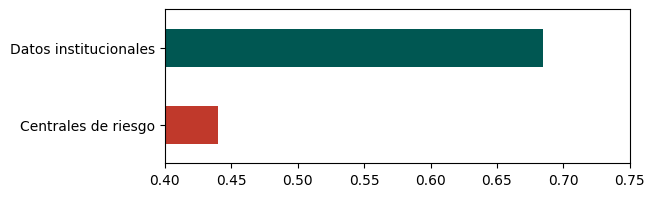

In [15]:
from scipy.stats import chi2_contingency

buro = ['conteo_alerta_financiero', 'conteo_financiero', 'conteo_alerta_cooperativo', 'conteo_cooperativo',
        'conteo_alerta_real', 'conteo_real', 'conteo_alerta_rotativos', 'conteo_moras_3m', 'conteo_moras_6m',
        'conteo_moras_12m', 'endeudamiento_julio2024', 'total_prod_alerta']
auc_buro = auc_cv(maduro, buro, ['nivel_endeudamiento'])
auc_inst = auc_cv(maduro, ['ingreso_mensual_en_smlmv', 'meses_afiliado', 'total_servicios_usados'], ['cargo_grupo', 'segmento_grupo'])
p_chi2 = chi2_contingency(pd.crosstab(maduro.conteo_moras_12m > 0, maduro.target))[1]

print(f"AUC sobre el incumplimiento interno: centrales {auc_buro:.3f} | datos institucionales {auc_inst:.3f}")
print(f"Chi-cuadrado, mora externa vs incumplimiento interno: p = {p_chi2:.3f}")
pd.Series({'Centrales de riesgo': auc_buro, 'Datos institucionales': auc_inst}).plot.barh(color=['#C0392B', '#005752'], xlim=(.4, .75), figsize=(6, 2))

- **No es *leakage*.** El 34,0% de quienes no tienen cupo ya registra moras y el 97,1% tiene productos en el sector real. Son datos de centrales, disponibles antes de otorgar.
- **Pero no sirven para este objetivo.** Las centrales dan un AUC de 0,440 contra 0,685 de los datos institucionales, y el chi-cuadrado (p = 0,943) no encuentra asociación. Con 56 eventos, 0,44 es compatible con 0,50: no predicen, y tampoco predicen al revés.
- Conclusión de negocio: el score de las centrales no ordena el riesgo **interno** de la caja. Se excluyen por falta de poder, no por trampa.

## Selección de variables: de 42 a 8

**Pregunta de negocio.** ¿Qué información de la caja vale la pena pedirle a un solicitante?
**Método.**
- **Exclusiones por criterio:** el límite del cupo lo fijó el analista (usarlo haría que el modelo copie su discrecionalidad, y no existe para un solicitante nuevo), la antigüedad laboral repite los meses de afiliación, el nivel educativo estimado es el cargo con otro nombre, y las centrales no predicen (sección anterior).
- **Selección incremental:** se agrega una variable a la vez y se mide el AUC con validación cruzada repetida. Con 56 incumplimientos, la regla práctica de **10 eventos por variable** pide pocas variables.

In [16]:
candidatas = [('Ingreso', ['ingreso_mensual_en_smlmv'], []), ('+ Cargo', [], ['cargo_grupo']),
              ('+ Meses de afiliación', ['meses_afiliado'], []), ('+ Uso de servicios', ['total_servicios_usados'], []),
              ('+ Segmento', [], ['segmento_grupo']), ('+ Edad (probada)', ['edad'], []),
              ('+ Ingreso per cápita (probada)', ['ingreso_per_capita'], []), ('+ Actividad de la empresa (probada)', [], ['actividad_de_la_empresa'])]
num, cat, curva = [], [], []
for nombre, n, c in candidatas:
    num, cat = num + n, cat + c
    curva.append((nombre, round(auc_cv(maduro, num, cat), 4)))
pd.DataFrame(curva, columns=['variable agregada', 'AUC']).set_index('variable agregada')

,AUC
variable agregada,
Ingreso,0.6757
+ Cargo,0.7166
+ Meses de afiliación,0.6914
+ Uso de servicios,0.6812
+ Segmento,0.6846
+ Edad (probada),0.6849
+ Ingreso per cápita (probada),0.6830
+ Actividad de la empresa (probada),0.6370


**Lectura.**
- El AUC **sube de 0,676 a 0,717 al agregar el cargo** y después no mejora: con meses, servicios y segmento queda entre 0,68 y 0,69. Edad, ingreso per cápita y actividad de la empresa tampoco aportan (la actividad, con 20 categorías para 56 eventos, empeora a 0,637).
- Hay que decirlo con honestidad: **el máximo está en dos variables, ingreso y cargo**. La diferencia con las cinco variables (0,03) es menor que la variación entre particiones (0,06) y no es significativa (se prueba en la Parte B). La estadística no obliga a elegir una u otra.
- Se conserva el modelo de **cinco variables por criterio de negocio**: el tiempo de afiliación, el uso de servicios y el segmento describen la relación del afiliado con la caja y permiten explicar el riesgo en esos términos. Queda documentada la alternativa más simple de dos variables.

## Segmentación K-Means: ¿a quién representa el modelo?

**Pregunta de negocio.** El modelo aprende de los afiliados que ya tuvieron cupo. ¿Esos afiliados se parecen a toda la población a la que se le quiere aplicar?
**Método.** Se agrupa a **toda la base** (con y sin cupo) en 8 segmentos con **K-Means** sobre las variables del modelo, estandarizadas para que el ingreso no domine a los meses. Un segmento tiene respaldo empírico si cumple un criterio mínimo: **al menos 10 incumplimientos observados y 15% de cobertura** (afiliados con cupo sobre total del segmento).

In [17]:
from sklearn.cluster import KMeans

def construir_X(df):
    """3 variables numéricas + cargo y segmento codificados = 8 columnas."""
    X = pd.concat([df[['ingreso_mensual_en_smlmv', 'meses_afiliado', 'total_servicios_usados']],
                   pd.get_dummies(df[['cargo_grupo', 'segmento_grupo']], drop_first=True)], axis=1).astype(float)
    return X.fillna(X.median())

X_todos = construir_X(d)
d['segmento_km'] = KMeans(n_clusters=8, n_init=20, random_state=42).fit_predict(StandardScaler().fit_transform(X_todos))

In [18]:
mapa = d.groupby('segmento_km').agg(afiliados=('tiene_cupo', 'size'), con_cupo=('tiene_cupo', 'sum'), incumplimientos=('target', 'sum'),
                                    ingreso_mediano=('ingreso_mensual_en_smlmv', 'median'), meses_afiliado_mediano=('meses_afiliado', 'median'))
mapa['cobertura_%'] = (mapa.con_cupo / mapa.afiliados * 100).round(1)
mapa['respaldo'] = (mapa.incumplimientos >= 10) & (mapa['cobertura_%'] >= 15)
print(f"Segmentos con respaldo: {mapa[mapa.respaldo].afiliados.sum():,} afiliados ({mapa[mapa.respaldo].afiliados.sum() / len(d):.1%} de la base)")
mapa.sort_values('afiliados', ascending=False)

Segmentos con respaldo: 2,885 afiliados (57.7% de la base)


,afiliados,con_cupo,incumplimientos,ingreso_mediano,meses_afiliado_mediano,cobertura_%,respaldo
segmento_km,,,,,,,
0,1892,354,67.0,1.10,19.0,18.7,True
2,948,15,2.0,1.30,9.0,1.6,False
1,760,284,33.0,1.80,30.0,37.4,True
5,534,66,3.0,1.80,15.0,12.4,False
3,468,95,1.0,3.25,38.0,20.3,False
6,233,123,12.0,2.00,224.0,52.8,True
4,111,20,2.0,1.20,13.0,18.0,False
7,54,5,0.0,23.05,40.0,9.3,False


**Lectura.**
- Solo **3 de los 8 segmentos** cumplen el criterio de respaldo (al menos 10 incumplimientos y 15% de cobertura). Reúnen 2.885 afiliados, el **57,7% de la base**. Para el 42,3% restante el modelo extrapolaría.
- El caso más claro es el segmento 2: 948 afiliados, apenas 15 con cupo (1,6% de cobertura) y 9 meses de afiliación mediana. Son afiliados nuevos sobre los que casi no hay observaciones.
- El segmento 7 reúne ingresos muy altos (mediana de 23 salarios mínimos) con solo 5 cupos: el modelo no sabe cómo se comportan.
- No es una falla del modelo, es el límite de la información. Etiquetar a los sin cupo por parecido propagaría los supuestos del propio modelo (circularidad), y no hay registro de solicitudes rechazadas para inferirlos.

# Parte B. Modelo

## Universo de modelado: maduración

**Pregunta de negocio.** ¿Con quiénes se puede construir un modelo justo?

**Método.** Se mide la tasa de incumplimiento según los meses de afiliación. Quien se afilió hace poco aún no tuvo tiempo de incumplir, y mezclarlo con los antiguos hace que el modelo confunda "reciente" con "buen pagador". Es el **sesgo de maduración**, y por eso se trabaja con 24 meses o más.

Universo maduro: 599 afiliados, 56 incumplimientos (9.3%), 8 columnas


<Axes: xlabel='meses_afiliado', ylabel='% de incumplimiento'>

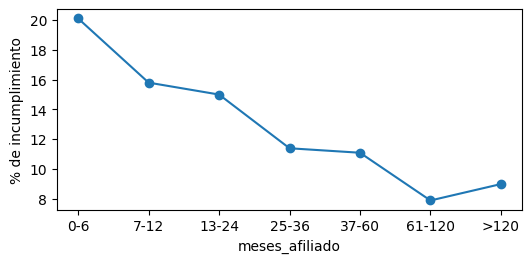

In [19]:
con_cupo = d[d.tiene_cupo == 1]
tramos = pd.cut(con_cupo.meses_afiliado, [0, 6, 12, 24, 36, 60, 120, 10000], labels=['0-6', '7-12', '13-24', '25-36', '37-60', '61-120', '>120'])
curva = con_cupo.groupby(tramos, observed=True).target.agg(n='size', incumplimientos='sum')
curva['tasa_%'] = (curva.incumplimientos / curva.n * 100).round(1)

X, y = X_todos.loc[maduro.index], maduro.target.astype(int).values
print(f"Universo maduro: {len(y)} afiliados, {y.sum()} incumplimientos ({y.mean():.1%}), {X.shape[1]} columnas")
curva['tasa_%'].plot(marker='o', figsize=(6, 2.6), ylabel='% de incumplimiento')

**Analisis.** La tasa de incumplimiento baja con la antigüedad: 20,1% en los primeros 6 meses y 7,9% entre 61 y 120 meses (el tramo de más de 120 sube a 9,0%, así que la caída no es perfecta). Por eso se modela con los **599 afiliados maduros, que suman 56 incumplimientos (9,3%)**. Se pierden 363 registros. Queda una limitación que conviene decir en voz alta: 56 eventos para 8 columnas son unos 7 por columna, por debajo de la regla de 10.

## Comparación de once algoritmos

**Pregunta de negocio.** ¿Un algoritmo más complejo detecta mejor el riesgo que uno simple?

**Método.** Once algoritmos, con las mismas 8 columnas y la misma validación (5 × 10). Métricas:
- **AUC:** probabilidad de que el modelo asigne más riesgo a quien incumplió que a quien no. 0,50 es azar; 1,00 es perfecto.
- **Gini** = 2 × AUC − 1.
- **KS:** distancia máxima entre las distribuciones de buenos y malos pagadores.
- **Brier:** error de las probabilidades. Un modelo puede ordenar bien y dar probabilidades irreales.

In [20]:
from sklearn.ensemble import AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

escalar = lambda m: make_pipeline(StandardScaler(), m)
modelos = {
    'Regresión logística (C=0,1)': escalar(LogisticRegression(C=0.1, max_iter=1000)),
    'Regresión logística (C=1,0)': escalar(LogisticRegression(C=1.0, max_iter=1000)),
    'Gradient Boosting (prof. 2)': GradientBoostingClassifier(n_estimators=80, max_depth=2, learning_rate=0.05, random_state=42),
    'Gradient Boosting (prof. 3)': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42),
    'Random Forest (prof. 3)': RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=30, random_state=42, n_jobs=2),
    'Random Forest (prof. 5)': RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20, random_state=42, n_jobs=2),
    'Extra Trees (prof. 4)': ExtraTreesClassifier(n_estimators=300, max_depth=4, min_samples_leaf=25, random_state=42, n_jobs=2),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    'Árbol de decisión (prof. 3)': DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=42),
    'KNN (k=25)': escalar(KNeighborsClassifier(n_neighbors=25)),
    'Naive Bayes': escalar(GaussianNB()),
}

In [21]:
from scipy.stats import ks_2samp
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
filas = []
for nombre, m in modelos.items():
    aucs = cross_val_score(m, X, y, cv=cv, scoring='roc_auc', n_jobs=2)
    p = cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
    filas.append((nombre, aucs.mean(), aucs.std(), 2 * roc_auc_score(y, p) - 1, ks_2samp(p[y == 0], p[y == 1]).statistic, brier_score_loss(y, p)))
tabla = pd.DataFrame(filas, columns=['Modelo', 'AUC', 'Desv', 'Gini', 'KS', 'Brier']).sort_values('AUC', ascending=False)
tabla.round(3).reset_index(drop=True)

,Modelo,AUC,Desv,Gini,KS,Brier
0,Gradient Boosting (prof. 2),0.711,0.065,0.441,0.394,0.083
1,AdaBoost,0.703,0.055,0.431,0.388,0.132
2,Gradient Boosting (prof. 3),0.701,0.065,0.371,0.343,0.087
3,Random Forest (prof. 3),0.697,0.069,0.360,0.410,0.082
4,Random Forest (prof. 5),0.691,0.066,0.357,0.407,0.082
5,Extra Trees (prof. 4),0.689,0.062,0.316,0.300,0.083
6,"Regresión logística (C=1,0)",0.685,0.058,0.338,0.315,0.083
7,"Regresión logística (C=0,1)",0.685,0.059,0.323,0.301,0.082
8,Árbol de decisión (prof. 3),0.676,0.056,0.348,0.347,0.083
9,Naive Bayes,0.673,0.055,0.265,0.307,0.669


**Lectura.**
- El mejor AUC es de **Gradient Boosting de profundidad 2 (0,711)**, seguido de AdaBoost (0,703). La logística queda en 0,685, a 0,026 del primero.
- Las desviaciones entre particiones (0,055 a 0,069) son del mismo tamaño que las diferencias entre modelos, y eso anticipa la conclusión de la sección siguiente.
- El Brier separa a quienes solo ordenan de quienes además dan probabilidades creíbles: AdaBoost (0,132) y Naive Bayes (0,669) están muy mal calibrados.
- Los modelos complejos no se despegan: con 56 eventos hay poco que aprender más allá de relaciones simples.

## ¿La diferencia es real o es ruido?

**Pregunta de negocio.** El mejor AUC es de Gradient Boosting. ¿Esa ventaja justifica un modelo más difícil de explicar?
**Método.** Se compara con la logística en las 50 particiones, de dos maneras. El *t* pareado ingenuo supone que las particiones son independientes, pero comparten la mayoría de los datos, y por eso declara significativas diferencias que no lo son. La **corrección de Nadeau y Bengio (2003)** ajusta la varianza por esa dependencia.

In [22]:
from scipy import stats
from sklearn.base import clone

def comparar_pareado(Xa, Xb, modelo_a, modelo_b):
    """Diferencia de AUC (A - B) en 50 particiones, con t ingenuo y t corregido."""
    dif = []
    for tr, te in cv.split(Xa, y):
        a = roc_auc_score(y[te], clone(modelo_a).fit(Xa.iloc[tr], y[tr]).predict_proba(Xa.iloc[te])[:, 1])
        b = roc_auc_score(y[te], clone(modelo_b).fit(Xb.iloc[tr], y[tr]).predict_proba(Xb.iloc[te])[:, 1])
        dif.append(a - b)
    dif = np.array(dif); n = len(dif)
    p = lambda se: 2 * (1 - stats.t.cdf(abs(dif.mean() / se), n - 1))
    se_c = np.sqrt((1 / n + 0.25) * dif.var(ddof=1))
    return dict(dif=dif.mean(), p_ingenuo=p(dif.std(ddof=1) / np.sqrt(n)), p_corregido=p(se_c),
                ic95=(dif.mean() - stats.t.ppf(.975, n - 1) * se_c, dif.mean() + stats.t.ppf(.975, n - 1) * se_c))

logit, gb = modelos['Regresión logística (C=0,1)'], modelos['Gradient Boosting (prof. 2)']
r = comparar_pareado(X, X, gb, logit)
print(f"Gradient Boosting - logística: {r['dif']:+.4f} de AUC | t ingenuo p = {r['p_ingenuo']:.4f} | t corregido p = {r['p_corregido']:.4f}")
print(f"IC 95% corregido: [{r['ic95'][0]:+.3f}, {r['ic95'][1]:+.3f}]")

Gradient Boosting - logística: +0.0268 de AUC | t ingenuo p = 0.0045 | t corregido p = 0.4210
IC 95% corregido: [-0.040, +0.093]


In [23]:
dos_vars = [c for c in X if c in ('ingreso_mensual_en_smlmv',) or c.startswith('cargo_grupo')]
r2 = comparar_pareado(X[dos_vars], X, logit, logit)
print(f"Logística de 2 variables (ingreso y cargo) - logística de 5 variables: {r2['dif']:+.4f} de AUC | t corregido p = {r2['p_corregido']:.3f}")

Logística de 2 variables (ingreso y cargo) - logística de 5 variables: +0.0320 de AUC | t corregido p = 0.201


**Lectura.**
- Gradient Boosting supera a la logística en 0,027 de AUC. El *t* ingenuo lo declara significativo (p = 0,0045), pero tratar las 50 particiones como independientes **infla la evidencia**. Con la corrección de Nadeau y Bengio el valor p es **0,42** y el intervalo de 95% va de −0,040 a +0,093, que incluye el cero.
- No podemos decir que el algoritmo complejo sea mejor. Tampoco que sea igual: con 56 eventos la prueba tiene poca potencia, y "no significativo" no equivale a "demostrado equivalente".
- La misma prueba entre el modelo de dos variables y el de cinco da 0,032 de diferencia con p = 0,20: tampoco concluyente. Con estos datos, ni la complejidad del algoritmo ni el número de variables se pueden justificar solo con el AUC.

## Modelo seleccionado: regresión logística

**Decisión.** El mejor AUC es de Gradient Boosting, pero la diferencia no es significativa. Entre dos modelos que no se distinguen, se prefiere el que se **explica a un comité**, produce **probabilidades calibradas** y rinde igual fuera de tiempo (se verifica al final). Desde aquí el análisis se enfoca en la regresión logística regularizada.

**Pregunta de negocio.** ¿Las probabilidades que entrega se pueden leer como probabilidades?

**Método.** Validación cruzada para el AUC y comparación del score medio con la tasa real. Se usa **sin ponderar por clase** (`class_weight='balanced'` distorsiona las probabilidades).

In [24]:
p = cross_val_predict(logit, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
aucs = cross_val_score(logit, X, y, cv=cv, scoring='roc_auc')
print(f"AUC (CV 5x10): {aucs.mean():.3f} ± {aucs.std():.3f}")
print(f"Gini {2 * roc_auc_score(y, p) - 1:.3f} | KS {ks_2samp(p[y == 0], p[y == 1]).statistic:.3f} | Brier {brier_score_loss(y, p):.4f}")
print(f"Calibración: score medio {p.mean():.3f} vs tasa real {y.mean():.3f}")

AUC (CV 5x10): 0.685 ± 0.059
Gini 0.323 | KS 0.301 | Brier 0.0825
Calibración: score medio 0.092 vs tasa real 0.093


El AUC de 0,685 ± 0,059: un poder discriminante **moderado**, lejos de lo que suele considerarse bueno (0,80). El Gini (0,323) y el KS (0,301) cuentan lo mismo. La calibración sí es buena: el score medio (0,092) coincide con la tasa real (0,093), así que las probabilidades se pueden leer como probabilidades. Sirve para ordenar y segmentar, no para decidir caso por caso.

## Qué pesa en el riesgo: razones de odds

**Pregunta de negocio.** ¿Qué características del afiliado suben o bajan el riesgo, y cuánto?
**Método.** La **razón de odds** es el factor por el que se multiplica la chance de incumplir al cambiar la variable en una unidad: mayor que 1 aumenta el riesgo, menor que 1 lo reduce. El ingreso se mide por salario mínimo, el tiempo de afiliación **por año** y el uso por servicio adicional.

In [25]:
modelo = logit.fit(X, y)
coef = pd.Series(modelo[-1].coef_[0] / modelo[0].scale_, index=X.columns)      # efecto por unidad real
coef['meses_afiliado'] *= 12                                                    # por cada 12 meses
razones = np.exp(coef).to_frame('razón de odds')
razones['cambio en el riesgo (%)'] = ((razones['razón de odds'] - 1) * 100).round(1)
razones.round(3)

,razón de odds,cambio en el riesgo (%)
ingreso_mensual_en_smlmv,0.884,-11.6
meses_afiliado,1.015,1.5
total_servicios_usados,0.971,-2.9
cargo_grupo_Operativo,2.226,122.6
cargo_grupo_Otros,0.279,-72.1
cargo_grupo_Prof_Dir,0.516,-48.4
segmento_grupo_Joven_Alto,0.655,-34.5
segmento_grupo_Medio,0.629,-37.1


El grupo de referencia del cargo es administrativo y técnico.
- **Cargo operativo:** el riesgo se multiplica por 2,2. Es el efecto más grande. Profesional y directivo lo reduce 48% y "otros" (que incluye los "Sin Definir") 72%.
- **Ingreso:** cada salario mínimo adicional baja el riesgo 11,6%.
- **Segmentos Medio y Joven/Alto:** riesgo 35% y 37% menor que el básico.
- **Tiempo de afiliación y servicios:** efectos pequeños. Cada año de afiliación sube el riesgo 1,5% y cada servicio adicional lo baja 2,9%, casi nulos en la práctica.

No se calcularon intervalos de confianza y, con 56 eventos, serían anchos. Se leen como dirección y orden de magnitud, no como cifras exactas.

## Bandas de riesgo

**Pregunta de negocio.** ¿Cómo traducir el score en categorías que el analista pueda usar?
**Método.** Se ordena a los afiliados por score y se parten en 2, 3, 4 y 5 grupos iguales. Una clasificación de riesgo defendible es **monótona**: la tasa de incumplimiento sube de banda en banda. Con pocos eventos, demasiadas bandas dejan que el ruido las desordene.

In [26]:
for k in (2, 3, 4, 5):
    tasas = (pd.Series(y).groupby(pd.qcut(p, k, labels=False)).mean() * 100).round(1)
    print(f"{k} bandas: {tasas.tolist()} -> {'monótona' if tasas.is_monotonic_increasing else 'NO monótona'}")

2 bandas: [6.0, 12.7] -> monótona
3 bandas: [2.5, 9.5, 16.0] -> monótona
4 bandas: [2.0, 10.0, 10.1, 15.3] -> monótona
5 bandas: [1.7, 6.7, 9.2, 15.8, 13.3] -> NO monótona


In [27]:
bandas = pd.qcut(p, 3, labels=['Bajo riesgo', 'Riesgo medio', 'Alto riesgo'])
tabla3 = pd.Series(y).groupby(bandas, observed=True).agg(afiliados='size', incumplimientos='sum')
tabla3['tasa_%'] = (tabla3.incumplimientos / tabla3.afiliados * 100).round(1)
tabla3

,afiliados,incumplimientos,tasa_%
Bajo riesgo,200,5,2.5
Riesgo medio,199,19,9.5
Alto riesgo,200,32,16.0


 Con 2, 3 y 4 bandas el riesgo crece, aunque con 4 las dos centrales casi empatan (10,0% y 10,1%), y con **5 bandas ya no es monótono** (15,8% y luego 13,3%). Se elige **3 bandas: 2,5%, 9,5% y 16,0%**, una razón de 6,4 veces entre extremos. Es el resultado más útil para el negocio: aunque el AUC sea moderado, el modelo separa a quienes casi nunca incumplen de quienes incumplen una de cada seis veces. Más bandas estarían sobreajustadas.

## Backtesting: validación fuera de tiempo

**Pregunta de negocio.** El modelo, ¿sigue funcionando sobre afiliados más recientes que los que usó para aprender?
**Método.** Se entrena con quienes se afiliaron antes de un año de corte y se prueba con los posteriores, como en la vida real: el modelo se construye con el pasado y decide sobre el futuro. Se compara la logística con Gradient Boosting para verificar que la elección no cuesta estabilidad.

In [28]:
Xv, filas = X.values, []
for corte in (2015, 2018, 2020, 2022):
    tr = (maduro.anio_afiliacion < corte).values
    fila = {'corte': f'< {corte} / ≥ {corte}', 'n_entrena': tr.sum(), 'incumplimientos_prueba': y[~tr].sum()}
    for nombre, m in (('AUC logística', logit), ('AUC Gradient Boosting', gb)):
        fila[nombre] = roc_auc_score(y[~tr], clone(m).fit(Xv[tr], y[tr]).predict_proba(Xv[~tr])[:, 1])
    filas.append(fila)
pd.DataFrame(filas).round(3).set_index('corte')

,n_entrena,incumplimientos_prueba,AUC logística,AUC Gradient Boosting
corte,,,,
< 2015 / ≥ 2015,189,39,0.708,0.730
< 2018 / ≥ 2018,289,29,0.645,0.655
< 2020 / ≥ 2020,357,24,0.649,0.637
< 2022 / ≥ 2022,466,11,0.737,0.741


**Analisis.**
- El AUC fuera de tiempo se mantiene entre 0,645 y 0,737, siempre sobre el azar: el modelo no se cae al cambiar de época.
- **La logística y Gradient Boosting rinden prácticamente igual** (diferencia máxima de 0,022; Gradient Boosting es algo mayor en tres de los cuatro cortes). La logística no aporta ventaja de estabilidad: se elige por interpretabilidad y calibración, no por rendimiento fuera de tiempo.
- La ventana más reciente tiene solo 11 incumplimientos en la prueba, así que su AUC de 0,737 es muy inestable. Con tan pocos eventos, el backtesting orienta pero no demuestra.

## Conclusiones

**Lo que demuestra el ejercicio.** Con cinco variables que la caja ya conoce (ingreso, cargo, segmento, tiempo de afiliación y uso de servicios) se puede ordenar el riesgo mejor que el azar, con probabilidades calibradas y efectos explicables. Pero gran parte del valor está en el **tratamiento de datos** (Parte A), no en el algoritmo:
- Elegir bien el objetivo: sin cupo es *no observado*, no "buen cliente".
- Auditar las centrales de riesgo antes de llamarlas *leakage*: son legítimas, pero no predicen el incumplimiento interno.
- Excluir a propósito lo que replica al analista (límite del cupo) o repite otra variable.
- Medir a quién representa el modelo antes de aplicarlo.

**Por qué la regresión logística.** Los algoritmos complejos no superan a la logística de forma demostrable, sus probabilidades son menos confiables y no se explican ante un comité como se explican las razones de odds. No se elige por estabilidad fuera de tiempo, donde rinden igual.

**Limitaciones que hay que decir en voz alta.**
- **Pocos incumplimientos:** 56 eventos para 8 columnas. Se compensa con regularización, validación repetida y backtesting, pero los intervalos son anchos.
- **Sesgo de selección:** solo se observa a quienes recibieron cupo; no hay solicitudes rechazadas.
- **Cobertura:** el modelo tiene respaldo empírico para el 57,7% de la base. Para el resto se requiere evaluación manual.
- **AUC moderado:** sirve para ordenar y segmentar, no para decidir caso por caso.
- **Selección de variables abierta:** un modelo de dos variables rinde igual (diferencia no significativa).
- **Sin fecha de otorgamiento ni de mora:** el incumplimiento se observa en un solo corte.


## Referencias
1. Hand, D. J. y Henley, W. E. (1997). Statistical classification methods in consumer credit scoring: a review. *J. R. Stat. Soc. A*, 160(3), 523-541.
2. Basel Committee on Banking Supervision (2006). *International Convergence of Capital Measurement and Capital Standards: A Revised Framework*, párr. 452.
3. Lessmann, S., Baesens, B., Seow, H.-V. y Thomas, L. C. (2015). Benchmarking state-of-the-art classification algorithms for credit scoring. *Eur. J. Oper. Res.*, 247(1), 124-136.
4. Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239-281.
5. Hosmer, D. W., Lemeshow, S. y Sturdivant, R. X. (2013). *Applied Logistic Regression* (3.ª ed.). Wiley.